In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 4.6 — Tensor product action

**Source:** SMSA 7.8, 2026-11-05, §4.6.1–4.6.6, equations (4.62)–(4.65). Local source: `smsa.pdf`. Source SHA-256: `6922b174be6719adbe0bfa0573cce44f0e5a7a54c4fafd5e43969c952813b8fe`.

**Translation conventions.** SMSA reads diagrams bottom to top. These unmodified native DisCoPy drawings read top to bottom: inputs are above outputs. Tensor factors retain their left-to-right order. `f >> g` means SMSA's $g\circ f$; `f @ g` means $f\otimes g$. The empty type represents the invisible unit wire. Coupons stand for the named SMSA maps even when SMSA uses a branching vertex. No custom functions or rewrite rules are introduced.

Checks print their computed objects and comparison results and continue when a mathematical comparison is false. A comparison in a concrete tensor model establishes only that model instance.

To translate (4.64), first copy the group-basis input with `Delta`, then swap the middle group and vector wires before applying the two action coupons. `@` in this expression is the ordinary tensor product of maps. The entire composite implements the tensor product representation. We again use the regular action of $\mathbb Z_2$ as explicit data.

In [1]:
from discopy import symmetric, tensor
from discopy.drawing import Equation
import numpy as np

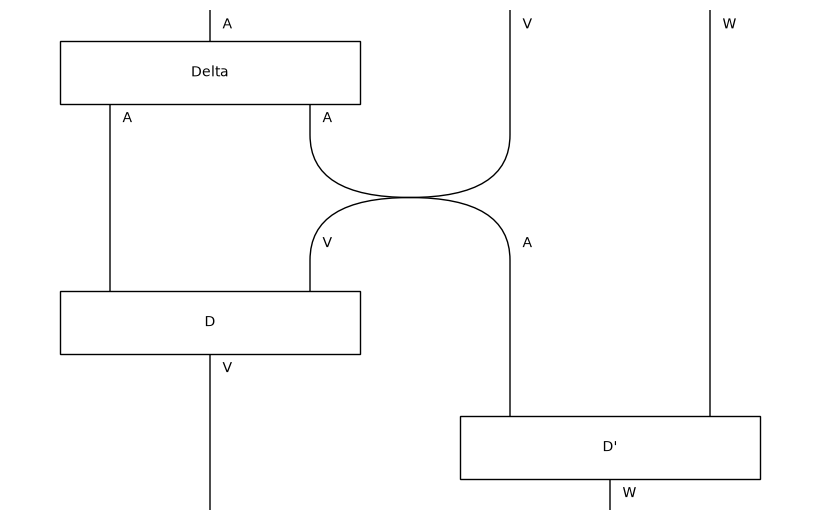

In [2]:
A, V, W = map(symmetric.Ty, ['A', 'V', 'W'])
Delta = symmetric.Box('Delta', A, A @ A)
rho = symmetric.Box('D', A @ V, V)
sigma = symmetric.Box("D'", A @ W, W)
action = (Delta @ symmetric.Id(V @ W)) >> (symmetric.Id(A) @ symmetric.Swap(A, V) @ symmetric.Id(W)) >> (rho @ sigma)
coefficients = [[[int(k == (i + j) % 2) for k in range(2)] for j in range(2)] for i in range(2)]
F = tensor.Functor({A: 2, V: 2, W: 2}, {Delta: [[[int(i == j == k) for k in range(2)] for j in range(2)] for i in range(2)], rho: coefficients, sigma: coefficients}, dom=symmetric.Category(), dtype=int)
action.draw(figsize=(8, 5))

In [3]:
computed = F(action).array
for g in range(2):
    Dg = F(rho).array[g].T
    Dprimeg = F(sigma).array[g].T
    actual = computed[g].reshape(4, 4).T
    expected = np.kron(Dg, Dprimeg)
    print('(4.62), group basis label', g, '\nActual:\n', actual, '\nExpected:\n', expected, '\nEqual:', np.array_equal(actual, expected))

(4.62), group basis label 0 
Actual:
 [[1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]] 
Expected:
 [[1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]] 
Equal: True
(4.62), group basis label 1 
Actual:
 [[0 0 0 1]
 [0 0 1 0]
 [0 1 0 0]
 [1 0 0 0]] 
Expected:
 [[0 0 0 1]
 [0 0 1 0]
 [0 1 0 0]
 [1 0 0 0]] 
Equal: True


DisCoPy flattens tensor parentheses; the associativity isomorphism in (4.65) is represented strictly. Its distinct bracketed source and target are suppressed. The coproduct copies basis labels linearly; it does not clone an arbitrary superposition.